# Diabetes status classification — Decision tree

**Dataset:** `diabetes_binary_5050split_health_indicators_BRFSS2015.csv` from DTU Learn. Set `DATA_PATH` below to its local location. Run cells in order. Install dependencies if needed: `pip install numpy pandas scikit-learn matplotlib seaborn`.

The label `Diabetes_binary` denotes reported (pre)diabetes **at survey time**. The dataset was deliberately balanced 50/50. A predicted probability is therefore a model score for this sampled population, **not** an individual's future absolute risk. Feature contributions describe the model, not causal effects or medical advice. Keep the held-out test set untouched while choosing settings.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, RocCurveDisplay,
                             brier_score_loss)
from sklearn.inspection import permutation_importance


In [2]:
DATA_PATH = Path('diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
SEED = 42
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Set DATA_PATH to the CSV downloaded from DTU Learn: {DATA_PATH.resolve()}')
df = pd.read_csv(DATA_PATH)
target = 'Diabetes_binary'
if target not in df:
    raise KeyError(f'Missing {target}; columns: {df.columns.tolist()}')
if df.columns.duplicated().any():
    raise ValueError('Duplicate column names')
X = df.drop(columns=target).apply(pd.to_numeric, errors='raise')
y = df[target].astype(int)
assert set(y.unique()) == {0, 1}, 'Expected binary label 0/1'
print('Rows, features:', X.shape, '| positive fraction:', round(y.mean(), 3))
print('Missing values:', int(X.isna().sum().sum()))
display(X.head())

# Identical split in both notebooks. Split before fitting any imputation/scaling.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
features = X.columns.tolist()


Rows, features: (70692, 21) | positive fraction: 0.5
Missing values: 0


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,1.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


## Train a shallow, readable decision tree

Imputation is fitted only on training data. `max_depth` and `min_samples_leaf` constrain complexity; these are baseline settings, not tuned on the test set.

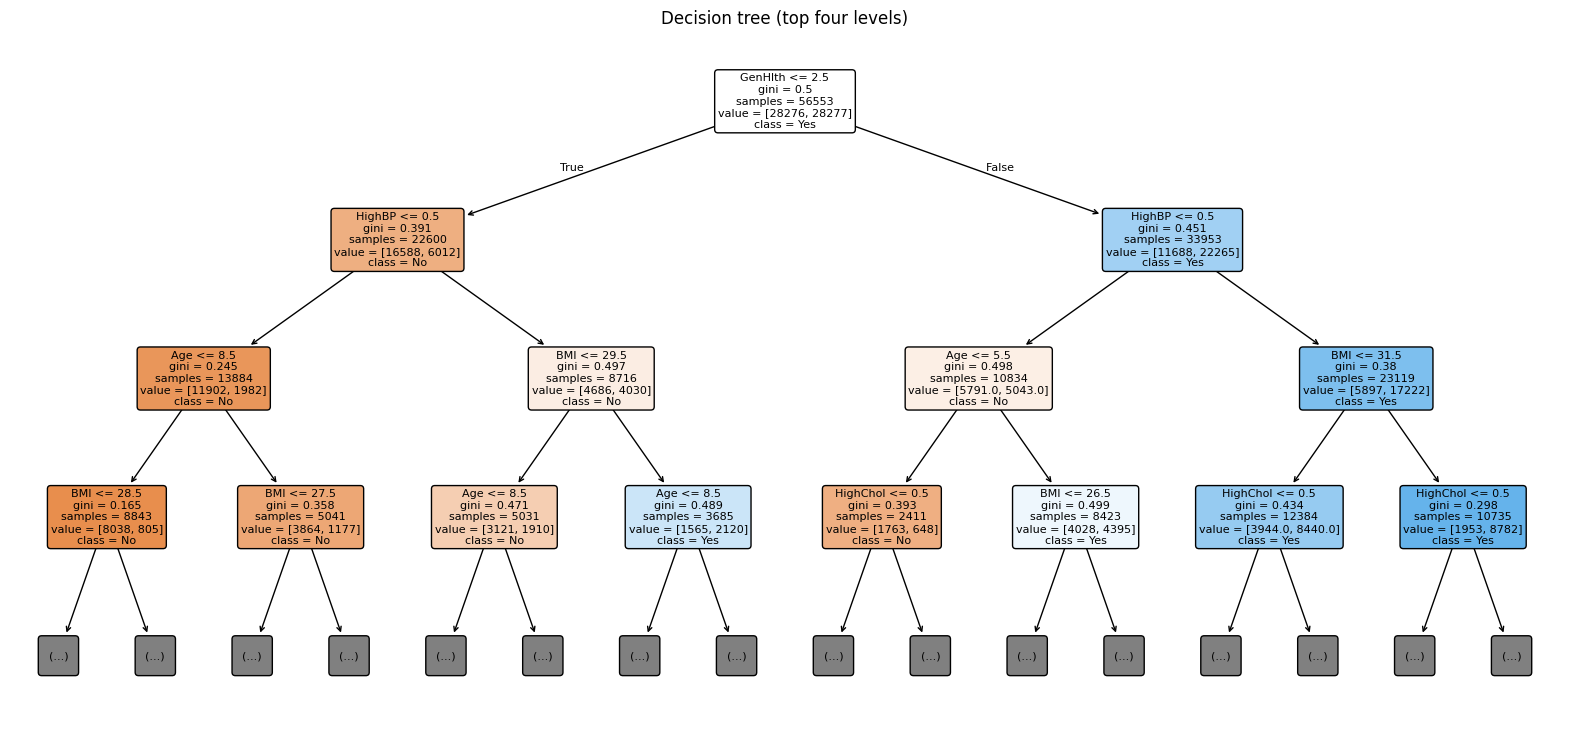

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree

model = make_pipeline(SimpleImputer(strategy='median'),
                      DecisionTreeClassifier(max_depth=4, min_samples_leaf=100,
                                             random_state=SEED))
model.fit(X_train, y_train)
probabilities = model.predict_proba(X_test)[:, 1]
plt.figure(figsize=(20, 9))
plot_tree(model[-1], feature_names=features, class_names=['No', 'Yes'],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title('Decision tree (top four levels)'); plt.show()


## Held-out evaluation

                  precision    recall  f1-score   support

no (pre)diabetes       0.75      0.68      0.71      7070
   (pre)diabetes       0.71      0.78      0.74      7069

        accuracy                           0.73     14139
       macro avg       0.73      0.73      0.73     14139
    weighted avg       0.73      0.73      0.73     14139

ROC AUC: 0.795
Average precision: 0.752
Brier score (balanced sample only): 0.182


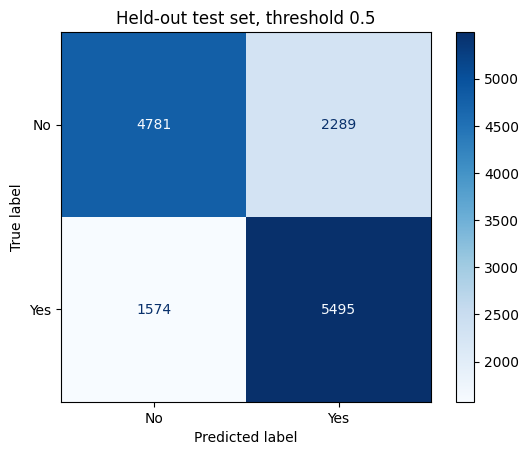

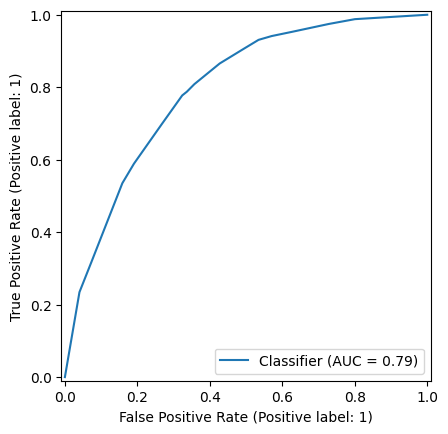

In [4]:
def evaluate(y_true, probability, threshold=0.5):
    prediction = (probability >= threshold).astype(int)
    print(classification_report(y_true, prediction, target_names=['no (pre)diabetes', '(pre)diabetes']))
    print(f'ROC AUC: {roc_auc_score(y_true, probability):.3f}')
    print(f'Average precision: {average_precision_score(y_true, probability):.3f}')
    print(f'Brier score (balanced sample only): {brier_score_loss(y_true, probability):.3f}')
    ConfusionMatrixDisplay.from_predictions(y_true, prediction, display_labels=['No', 'Yes'], cmap='Blues')
    plt.title('Held-out test set, threshold 0.5'); plt.show()
    RocCurveDisplay.from_predictions(y_true, probability); plt.show()

evaluate(y_test, probabilities)


## Global explanation: permutation importance
### We check for collinearity between features.

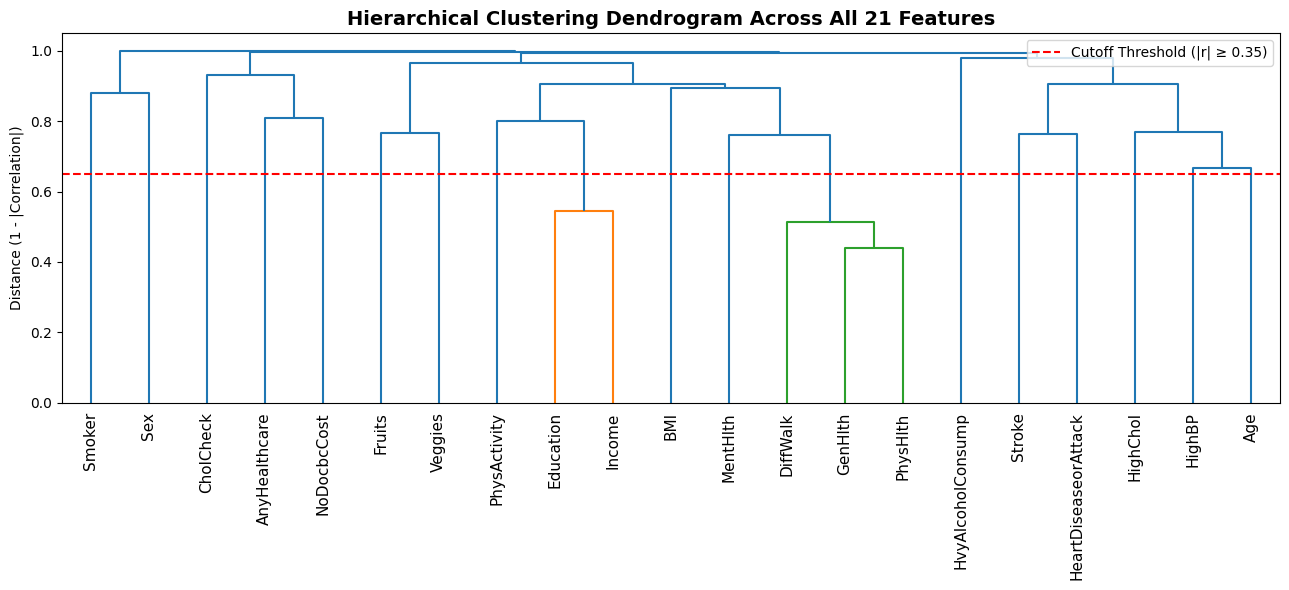

=== Mathematically Derived Feature Clusters (|r| ≥ 0.35) ===

Cluster 15 (Single Feature): HighBP
Cluster 17 (Single Feature): HighChol
Cluster 5 (Single Feature): CholCheck
Cluster 12 (Single Feature): BMI
Cluster 1 (Single Feature): Smoker
Cluster 13 (Single Feature): Stroke
Cluster 14 (Single Feature): HeartDiseaseorAttack
Cluster 9 (Single Feature): PhysActivity
Cluster 6 (Single Feature): Fruits
Cluster 7 (Single Feature): Veggies
Cluster 18 (Single Feature): HvyAlcoholConsump
Cluster 3 (Single Feature): AnyHealthcare
Cluster 4 (Single Feature): NoDocbcCost
Cluster 10 (Grouped): ['GenHlth', 'PhysHlth', 'DiffWalk']
Cluster 11 (Single Feature): MentHlth
Cluster 2 (Single Feature): Sex
Cluster 16 (Single Feature): Age
Cluster 8 (Grouped): ['Education', 'Income']


In [5]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform

# 1. Compute Pairwise Absolute Correlation Matrix across ALL features
corr_matrix = X_test.corr(method='pearson').abs()

# 2. Convert Correlation to Distance Matrix (Distance = 1 - |r|)
# Fill diagonal with 0 to prevent tiny floating-point rounding errors
dist_matrix = 1.0 - corr_matrix
np.fill_diagonal(dist_matrix.values, 0)

# Convert to condensed distance vector required by SciPy
condensed_dist = squareform(dist_matrix)

# 3. Perform Hierarchical Agglomerative Clustering (Complete Linkage)
linkage_matrix = linkage(condensed_dist, method='complete')

# 4. Plot the Dendrogram
plt.figure(figsize=(13, 6))
dendrogram(
    linkage_matrix,
    labels=X_test.columns,
    leaf_rotation=90,
    leaf_font_size=11,
    color_threshold=0.65,  # Highlights clusters with |r| >= 0.35
)

# Draw cutoff line corresponding to correlation threshold |r| = 0.35
plt.axhline(
    y=0.65, color='red', linestyle='--', label='Cutoff Threshold (|r| ≥ 0.35)'
)

plt.title(
    'Hierarchical Clustering Dendrogram Across All 21 Features',
    fontsize=14,
    fontweight='bold',
)
plt.ylabel('Distance (1 - |Correlation|)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# 5. Automatically Extract and Print Clusters
distance_threshold = 0.65  # Equivalent to |r| >= 0.35
cluster_ids = fcluster(
    linkage_matrix, t=distance_threshold, criterion='distance'
)

cluster_groups = {}
for feature, cid in zip(X_test.columns, cluster_ids):
  cluster_groups.setdefault(cid, []).append(feature)

print(
    '=== Mathematically Derived Feature Clusters (|r| ≥ 0.35) ===\n'
)
for cid, members in cluster_groups.items():
  if len(members) > 1:
    print(f'Cluster {cid} (Grouped): {members}')
  else:
    print(f'Cluster {cid} (Single Feature): {members[0]}')

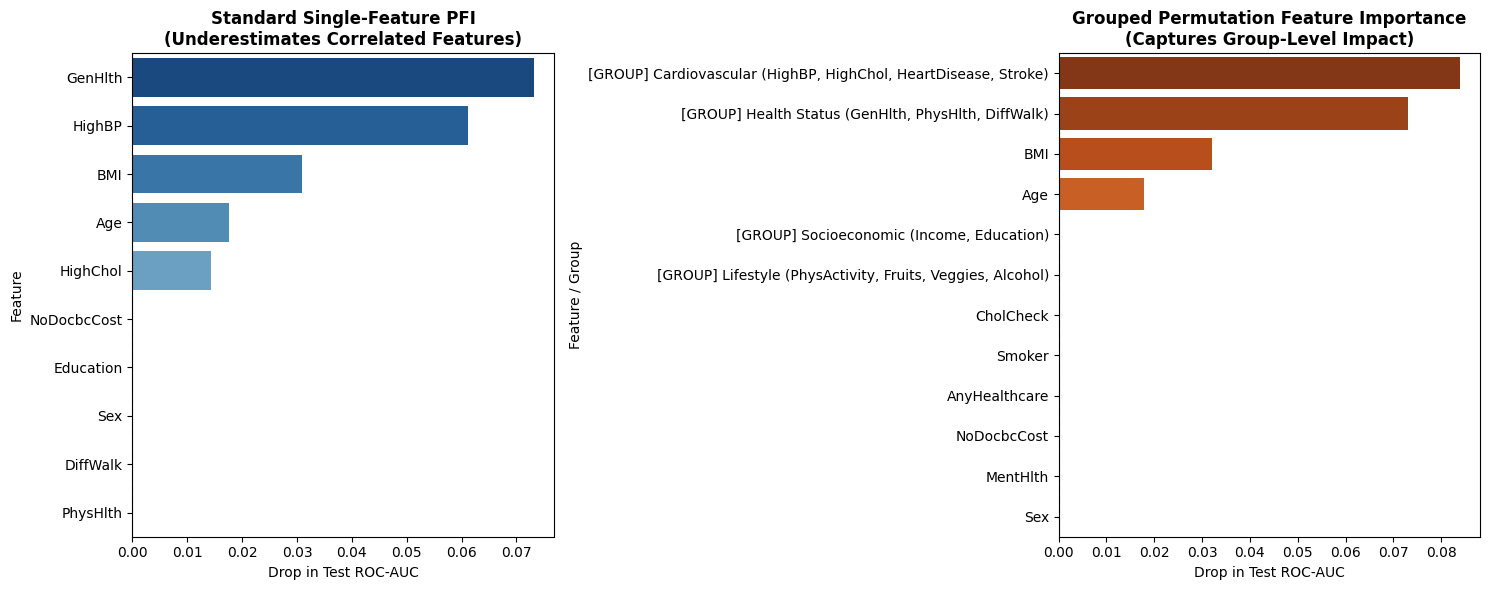

In [6]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
import seaborn as sns

# 1. Define groups of correlated features
feature_groups = {
    'Health Status (GenHlth, PhysHlth, DiffWalk)': [
        'GenHlth',
        'PhysHlth',
        'DiffWalk',
    ],
    'Socioeconomic (Income, Education)': ['Income', 'Education'],
    'Cardiovascular (HighBP, HighChol, HeartDisease, Stroke)': [
        'HighBP',
        'HighChol',
        'HeartDiseaseorAttack',
        'Stroke',
    ],
    'Lifestyle (PhysActivity, Fruits, Veggies, Alcohol)': [
        'PhysActivity',
        'Fruits',
        'Veggies',
        'HvyAlcoholConsump',
    ],
}

# 2. Compute Standard Single-Feature PFI
pfi_single = permutation_importance(
    model, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=42
)
df_single = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': pfi_single.importances_mean,
}).sort_values(by='Importance', ascending=False)

# 3. Compute Grouped PFI (Joint Shuffling)
baseline_score = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
all_grouped_cols = [col for cols in feature_groups.values() for col in cols]
ungrouped_cols = [col for col in X_test.columns if col not in all_grouped_cols]

grouped_records = []
n_repeats = 10

# Correlated Groups
for group_name, cols in feature_groups.items():
  existing_cols = [c for c in cols if c in X_test.columns]
  if not existing_cols:
    continue
  importances = []
  for r in range(n_repeats):
    X_test_perm = X_test.copy()
    perm_idx = np.random.RandomState(42 + r).permutation(len(X_test))
    for col in existing_cols:
      X_test_perm[col] = X_test[col].values[perm_idx]

    perm_score = roc_auc_score(y_test, model.predict_proba(X_test_perm)[:, 1])
    importances.append(baseline_score - perm_score)

  grouped_records.append({
      'Feature / Group': f'[GROUP] {group_name}',
      'Importance': np.mean(importances),
  })

# Ungrouped Individual Features
for col in ungrouped_cols:
  importances = []
  for r in range(n_repeats):
    X_test_perm = X_test.copy()
    perm_idx = np.random.RandomState(42 + r).permutation(len(X_test))
    X_test_perm[col] = X_test[col].values[perm_idx]

    perm_score = roc_auc_score(y_test, model.predict_proba(X_test_perm)[:, 1])
    importances.append(baseline_score - perm_score)

  grouped_records.append({'Feature / Group': col, 'Importance': np.mean(importances)})

df_grouped = pd.DataFrame(grouped_records).sort_values(
    by='Importance', ascending=False
)

# 4. Plot Side-by-Side Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=df_single.head(10),
    x='Importance',
    y='Feature',
    hue='Feature',
    ax=ax1,
    palette='Blues_r',
    legend=False,
)
ax1.set_title(
    'Standard Single-Feature PFI\n(Underestimates Correlated Features)',
    fontweight='bold',
)
ax1.set_xlabel('Drop in Test ROC-AUC')

sns.barplot(
    data=df_grouped,
    x='Importance',
    y='Feature / Group',
    hue='Feature / Group',
    ax=ax2,
    palette='Oranges_r',
    legend=False,
)
ax2.set_title(
    'Grouped Permutation Feature Importance\n(Captures Group-Level Impact)',
    fontweight='bold',
)
ax2.set_xlabel('Drop in Test ROC-AUC')

for ax in (ax1, ax2):
  ax.axvline(0, color='gray', linestyle='--')

plt.tight_layout()
plt.show()

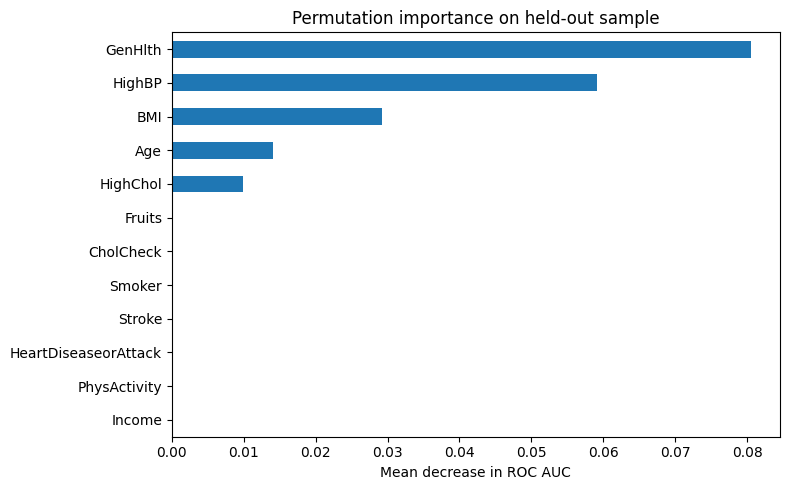

,mean_auc_drop
GenHlth,0.080549
HighBP,0.059089
BMI,0.029161
Age,0.014040
HighChol,0.009934
HeartDiseaseorAttack,0.000000
Fruits,0.000000
CholCheck,0.000000
Smoker,0.000000
Stroke,0.000000


In [ ]:
# Global audit: drop in held-out ROC AUC after shuffling one feature.
sample = X_test.sample(n=min(2000, len(X_test)), random_state=SEED)
result = permutation_importance(model, sample, y_test.loc[sample.index],
                                scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=1)
importance = pd.Series(result.importances_mean, index=features).sort_values()
importance.tail(12).plot.barh(figsize=(8, 5), xlabel='Mean decrease in ROC AUC')
plt.title('Permutation importance on held-out sample'); plt.tight_layout(); plt.show()
display(importance.sort_values(ascending=False).head(15).to_frame('mean_auc_drop'))


## Local explanation: exact decision path

The conditions below show why the tree assigned its leaf score. They do not estimate the effect of changing a feature.

In [8]:
row_position = 0  # Change to inspect another held-out person
row = X_test.iloc[[row_position]]
filled = model[0].transform(row)
tree_model = model[-1]
node_ids = tree_model.decision_path(filled).indices
for node in node_ids:
    feature_index = tree_model.tree_.feature[node]
    if feature_index < 0:
        break
    value = filled[0, feature_index]
    limit = tree_model.tree_.threshold[node]
    relation = '<=' if value <= limit else '>'
    print(f'{features[feature_index]} = {value:g} {relation} {limit:.3g}')
print('Model score:', round(model.predict_proba(row)[0, 1], 3))
print('True survey label:', int(y_test.iloc[row_position]))


GenHlth = 4 > 2.5
HighBP = 1 > 0.5
BMI = 53 > 31.5
HighChol = 1 > 0.5
Model score: 0.853
True survey label: 1


## Error audit

Review false negatives and false positives. Features such as `Age`, `Income`, and access to care may encode social patterns; differences in this dataset alone cannot establish fairness or clinical safety.

In [9]:
audit = X_test.copy()
audit['actual'] = y_test
audit['score'] = probabilities
audit['predicted'] = (probabilities >= 0.5).astype(int)
display(audit.loc[(audit.actual == 1) & (audit.predicted == 0)].sort_values('score').head(10))
display(audit.loc[(audit.actual == 0) & (audit.predicted == 1)].sort_values('score', ascending=False).head(10))


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,actual,score,predicted
69246,0.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,0.0,0.0,...,8.0,0.0,0.0,0.0,7.0,5.0,8.0,1,0.058439,0
37037,0.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,1.0,8.0,5.0,6.0,1,0.058439,0
46366,0.0,1.0,1.0,27.0,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,7.0,6.0,8.0,1,0.058439,0
67032,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,5.0,6.0,8.0,1,0.058439,0
67339,0.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,1.0,0.0,1.0,7.0,6.0,7.0,1,0.058439,0
66662,0.0,1.0,1.0,27.0,1.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,1.0,0.0,8.0,4.0,6.0,1,0.058439,0
40179,0.0,1.0,1.0,21.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,2.0,0.0,1.0,4.0,5.0,6.0,1,0.058439,0
59497,0.0,1.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,1.0,7.0,6.0,8.0,1,0.058439,0
50392,0.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,2.0,6.0,7.0,1,0.058439,0
44923,0.0,0.0,1.0,24.0,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,1.0,8.0,6.0,8.0,1,0.058439,0


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,actual,score,predicted
20389,1.0,1.0,1.0,44.0,1.0,0.0,1.0,0.0,0.0,0.0,...,14.0,30.0,0.0,1.0,7.0,4.0,4.0,0,0.852626,1
22803,1.0,1.0,1.0,35.0,0.0,0.0,0.0,0.0,0.0,1.0,...,30.0,2.0,0.0,1.0,4.0,3.0,4.0,0,0.852626,1
28180,1.0,1.0,1.0,35.0,1.0,0.0,0.0,0.0,0.0,0.0,...,30.0,27.0,1.0,0.0,9.0,5.0,4.0,0,0.852626,1
12515,1.0,1.0,1.0,33.0,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,10.0,3.0,1.0,0,0.852626,1
20119,1.0,1.0,1.0,37.0,1.0,0.0,0.0,0.0,1.0,1.0,...,10.0,6.0,0.0,0.0,9.0,5.0,3.0,0,0.852626,1
27604,1.0,1.0,1.0,34.0,1.0,0.0,0.0,1.0,1.0,1.0,...,30.0,30.0,1.0,0.0,9.0,5.0,6.0,0,0.852626,1
31500,1.0,1.0,1.0,51.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,5.0,1.0,1.0,7.0,2.0,4.0,0,0.852626,1
6426,1.0,1.0,1.0,45.0,1.0,0.0,0.0,0.0,0.0,1.0,...,8.0,30.0,1.0,0.0,7.0,2.0,3.0,0,0.852626,1
340,1.0,1.0,1.0,33.0,1.0,1.0,0.0,1.0,1.0,1.0,...,0.0,5.0,0.0,0.0,11.0,6.0,7.0,0,0.852626,1
28001,1.0,1.0,1.0,37.0,1.0,0.0,1.0,1.0,1.0,1.0,...,2.0,7.0,1.0,1.0,8.0,3.0,4.0,0,0.852626,1
